# CNN tự xây dựng: phân tích đặc trưng CIFAR-100

**Không huấn luyện lại.** Notebook nạp `best_cifar100_resnet_mixup.pth`, phân tích 10.000 ảnh test thuộc 100 lớp và xuất hình phục vụ so sánh với Swin-T.

## Cách chạy trên Kaggle
1. Import notebook này vào Kaggle.
2. **Add Input / Upload** checkpoint CNN đã train. File `.ipynb` không chứa trọng số.
3. Thêm dataset **CIFAR-100 Python** nếu có. Nếu không tìm thấy test/meta, notebook dùng torchvision để tải CIFAR-100 (cần bật Internet).
4. Bật GPU nếu có, rồi **Run All**. Notebook không chứa optimizer hoặc vòng lặp huấn luyện.
5. Cuối cùng tải `/kaggle/working/cnn_feature_visualization.zip` từ Output.

Nếu có nhiều checkpoint cùng tên, điền chính xác `CHECKPOINT_PATH` ở cell đầu. PCA/t-SNE chạy trên toàn bộ 10.000 ảnh và có thể mất nhiều thời gian trên CPU.

CNN dùng ảnh 32×32, vector 128 chiều. Swin dùng ảnh resize 224×224, vector 768 chiều. Hai model giữ preprocessing tương ứng khi train; so sánh trên cùng ảnh test, cùng thứ tự, seed và tham số phân tích.


In [1]:
from pathlib import Path
import copy, json, pickle, random, zipfile, inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms
from PIL import Image
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# Điền đường dẫn nếu có nhiều checkpoint, ví dụ /kaggle/input/.../best_cifar100_resnet_mixup.pth
CHECKPOINT_PATH = None
OUTPUT_DIR = Path('/kaggle/working/cnn_feature_results')
VIS_DIR = OUTPUT_DIR / 'feature_analysis'
VIS_DIR.mkdir(parents=True, exist_ok=True)
if CHECKPOINT_PATH is None:
    candidates = sorted(set(p.resolve() for root in (Path('/kaggle/input'), Path('/kaggle/working'))
                            if root.exists() for p in root.rglob('best_cifar100_resnet_mixup.pth')))
    if len(candidates) != 1:
        raise RuntimeError('Cần đúng 1 checkpoint. Upload file .pth hoặc đặt CHECKPOINT_PATH. Tìm thấy: '
                           + str([str(p) for p in candidates]))
    CHECKPOINT_PATH = candidates[0]
CHECKPOINT_PATH = Path(CHECKPOINT_PATH)
assert CHECKPOINT_PATH.is_file(), f'Không tìm thấy checkpoint: {CHECKPOINT_PATH}'
print('Thiết bị:', DEVICE, '| checkpoint:', CHECKPOINT_PATH)


Thiết bị: cuda | checkpoint: /kaggle/input/datasets/khcbnh/cifar100-resnet-mixup-checkpoint/best_cifar100_resnet_mixup.pth


## 1. Kiến trúc gốc và trọng số đã train
Giữ nguyên định nghĩa CIFARResNet của notebook CNN: 3 stage, mỗi stage 3 blocks, số kênh 32–64–128.


In [2]:
class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels, out_channels,
            kernel_size=3, stride=stride, padding=1, bias=False
        )
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)

        self.conv2 = nn.Conv2d(
            out_channels, out_channels,
            kernel_size=3, stride=1, padding=1, bias=False
        )
        self.bn2 = nn.BatchNorm2d(out_channels)

        # Điều chỉnh shortcut khi đổi số kênh hoặc kích thước ảnh
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(
                    in_channels, out_channels,
                    kernel_size=1, stride=stride, bias=False
                ),
                nn.BatchNorm2d(out_channels),
            )
        else:
            self.shortcut = nn.Identity()

    def forward(self, x):
        identity = self.shortcut(x)

        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))

        out = out + identity
        return self.relu(out)

class CIFARResNet(nn.Module):
    def __init__(self, num_classes=100, blocks_per_stage=3):
        super().__init__()

        # Giữ độ phân giải 32×32 ở đầu mạng
        self.stem = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
        )

        self.stage1 = self.make_stage(
            32, 32, blocks_per_stage, stride=1
        )  # 32×32

        self.stage2 = self.make_stage(
            32, 64, blocks_per_stage, stride=2
        )  # 16×16

        self.stage3 = self.make_stage(
            64, 128, blocks_per_stage, stride=2
        )  # 8×8

        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p=0.3),
            nn.Linear(128, num_classes),
        )

        self.initialize_weights()

    @staticmethod
    def make_stage(in_channels, out_channels, num_blocks, stride):
        layers = [
            ResidualBlock(in_channels, out_channels, stride=stride)
        ]
        for _ in range(1, num_blocks):
            layers.append(ResidualBlock(out_channels, out_channels))
        return nn.Sequential(*layers)

    def initialize_weights(self):
        for module in self.modules():
            if isinstance(module, nn.Conv2d):
                nn.init.kaiming_normal_(
                    module.weight, mode="fan_out", nonlinearity="relu"
                )
            elif isinstance(module, nn.BatchNorm2d):
                nn.init.ones_(module.weight)
                nn.init.zeros_(module.bias)
            elif isinstance(module, nn.Linear):
                nn.init.normal_(module.weight, mean=0.0, std=0.01)
                nn.init.zeros_(module.bias)

    def forward(self, x):
        x = self.stem(x)
        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)
        x = self.pool(x)
        return self.classifier(x)

model = CIFARResNet(num_classes=100)
checkpoint = torch.load(CHECKPOINT_PATH, map_location='cpu', weights_only=True)
state = checkpoint['model_state_dict'] if 'model_state_dict' in checkpoint else checkpoint
model.load_state_dict(state, strict=True)
model = model.to(DEVICE).eval()
print('Đã nạp checkpoint. Số tham số:', sum(p.numel() for p in model.parameters()))


Đã nạp checkpoint. Số tham số: 1096196


## 2. Tập test sạch
Không dùng MixUp, crop, flip hay rotation. Ưu tiên test/meta trong Kaggle Input; nếu không có thì tải bằng torchvision.


In [3]:
MEAN = (0.5071, 0.4867, 0.4408)
STD = (0.2675, 0.2565, 0.2761)
test_transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

class CIFAR100PickleTest(Dataset):
    def __init__(self, test_path, transform):
        with open(test_path, 'rb') as f: data = pickle.load(f, encoding='latin1')
        with open(test_path.parent / 'meta', 'rb') as f: meta = pickle.load(f, encoding='latin1')
        self.images = data['data'].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)
        self.targets = data['fine_labels']
        self.classes = meta['fine_label_names']
        self.transform = transform
    def __len__(self): return len(self.targets)
    def __getitem__(self, i):
        return self.transform(Image.fromarray(self.images[i])), self.targets[i]

# Có thể điền đường dẫn test pickle thủ công nếu gắn nhiều bản dataset.
TEST_PICKLE_PATH = None
if TEST_PICKLE_PATH is None:
    tests = sorted(p for p in Path('/kaggle/input').rglob('test')
                   if p.is_file() and (p.parent / 'meta').is_file())
    if len(tests) > 1:
        raise RuntimeError('Có nhiều dataset. Đặt TEST_PICKLE_PATH: ' + str(tests))
    TEST_PICKLE_PATH = tests[0] if tests else None
if TEST_PICKLE_PATH is not None:
    test_ds = CIFAR100PickleTest(Path(TEST_PICKLE_PATH), test_transform)
else:
    test_ds = datasets.CIFAR100('/kaggle/working/cifar100_data', train=False,
                               download=True, transform=test_transform)
class_names = list(test_ds.classes)
assert len(test_ds) == 10000 and len(class_names) == 100
assert np.all(np.bincount(test_ds.targets, minlength=100) == 100)
print('Test:', len(test_ds), 'ảnh |', len(class_names), 'lớp')


Test: 10000 ảnh | 100 lớp


## 3. Các bộ lọc convolution đầu tiên
32 kernel của stem, mỗi kernel có kích thước 3×3×3. Mỗi hình được chuẩn hóa riêng để hiển thị, không dùng để so sánh độ lớn trọng số.


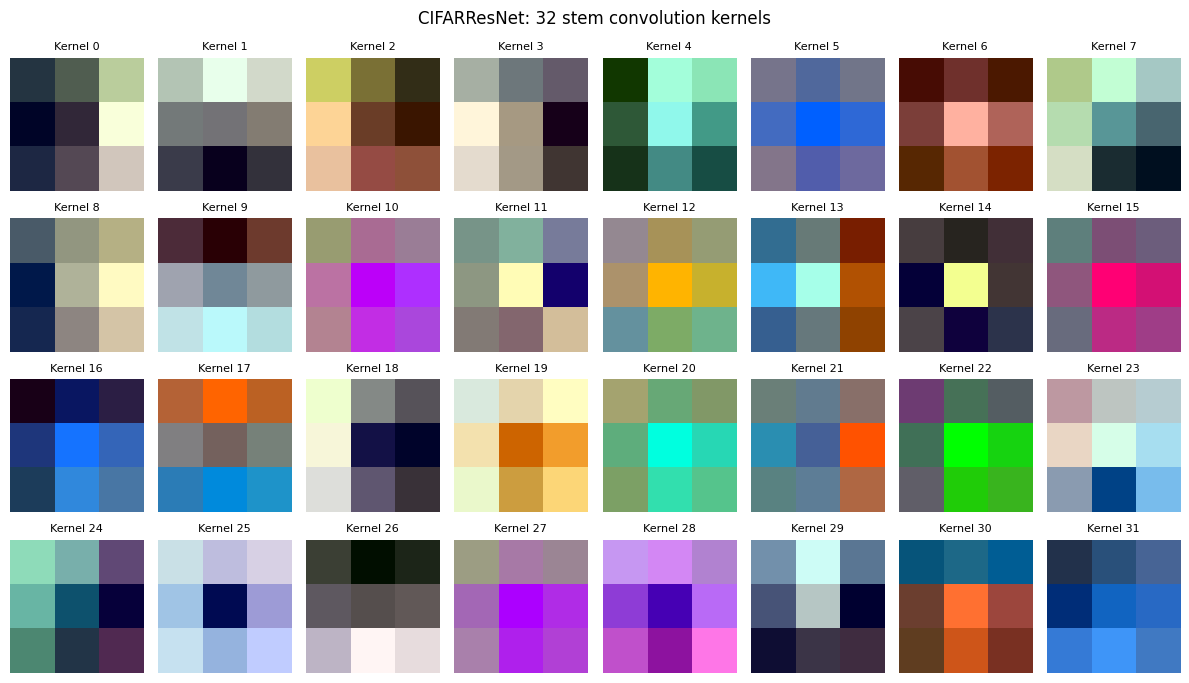

Weights: (32, 3, 3, 3)


In [4]:
kernels = model.stem[0].weight.detach().float().cpu().numpy()
fig, axes = plt.subplots(4, 8, figsize=(12, 7))
for i, ax in enumerate(axes.flat):
    v = kernels[i].transpose(1, 2, 0)
    v = (v - v.min()) / (v.max() - v.min() + 1e-8)
    ax.imshow(v, interpolation='nearest'); ax.set_title(f'Kernel {i}', fontsize=8); ax.axis('off')
fig.suptitle('CIFARResNet: 32 stem convolution kernels')
fig.tight_layout(); fig.savefig(VIS_DIR/'cnn_stem_filters.png', dpi=200, bbox_inches='tight')
plt.show(); plt.close(fig)
print('Weights:', kernels.shape)


## 4. Feature map của 3 stage
Dùng ảnh TEST index 0, giống notebook Swin-T. CNN trả NCHW, khác NHWC của Swin. Hiển thị 8 kênh đầu mỗi stage. Các kênh của hai model không tương ứng trực tiếp.


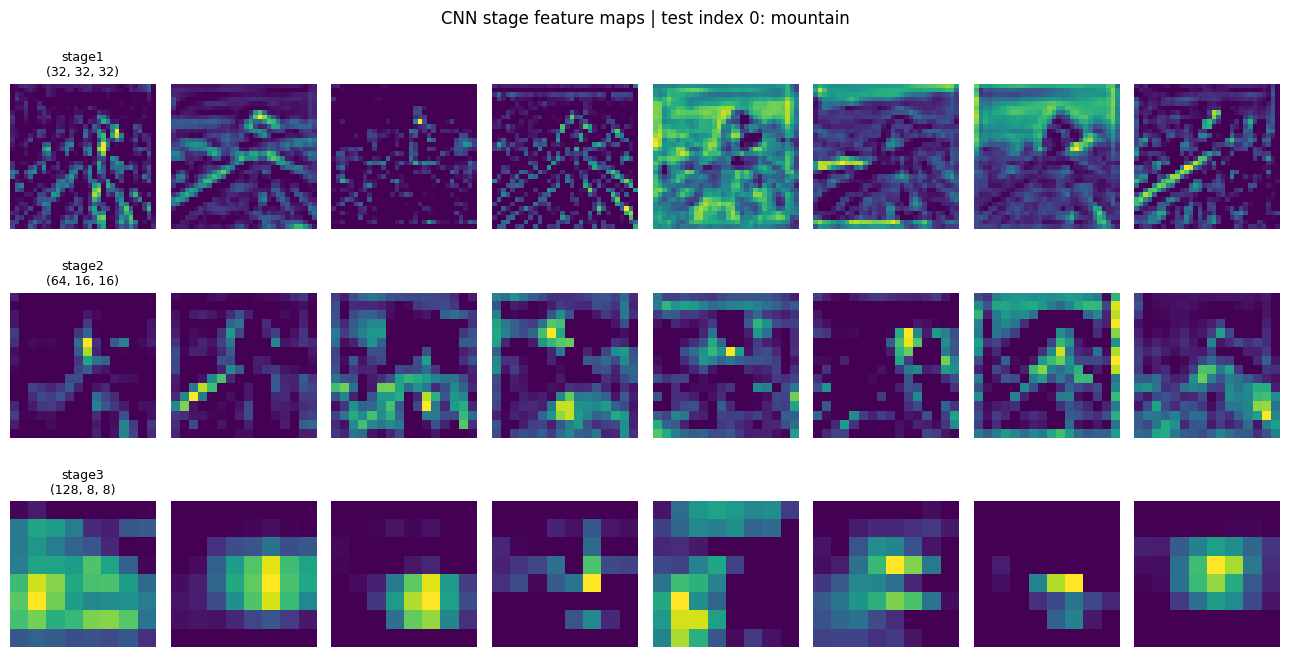

{'stage1': (1, 32, 32, 32), 'stage2': (1, 64, 16, 16), 'stage3': (1, 128, 8, 8)}


In [5]:
activations = {}
def capture(name):
    def hook(module, inputs, output): activations[name] = output.detach().float().cpu()
    return hook
hooks = [layer.register_forward_hook(capture(name)) for name, layer in
         {'stage1':model.stage1, 'stage2':model.stage2, 'stage3':model.stage3}.items()]
sample_image, sample_label = test_ds[0]
try:
    with torch.inference_mode(): model(sample_image.unsqueeze(0).to(DEVICE))
finally:
    for hook in hooks: hook.remove()
fig, axes = plt.subplots(3, 8, figsize=(13, 7))
for row, (name, tensor) in enumerate(activations.items()):
    for col in range(8):
        axes[row,col].imshow(tensor[0,col].numpy(), cmap='viridis')
        axes[row,col].axis('off')
        if col == 0: axes[row,col].set_title(f'{name}\n{tuple(tensor.shape[1:])}', fontsize=9)
fig.suptitle('CNN stage feature maps | test index 0: ' + class_names[sample_label])
fig.tight_layout(); fig.savefig(VIS_DIR/'cnn_stage_feature_maps.png', dpi=200, bbox_inches='tight')
plt.show(); plt.close(fig)
print({k: tuple(v.shape) for k,v in activations.items()})


## 5. Trích 10.000 vector 128 chiều
Lấy output sau GAP rồi Flatten, bỏ Dropout và Linear. Giữ nguyên thứ tự test và lưu manifest để đối chiếu với Swin.


In [6]:
SELECTED_CLASS_IDS = list(range(100))
indices = list(range(len(test_ds)))
analysis_loader = DataLoader(test_ds, batch_size=128, shuffle=False, num_workers=0, drop_last=False)
feature_model = copy.deepcopy(model)
feature_model.classifier = nn.Flatten()
feature_model.eval()
vectors, labels = [], []
with torch.inference_mode():
    for images, targets in tqdm(analysis_loader, desc='CNN: extracting 10000 features'):
        # FP32 như notebook CNN khi huấn luyện.
        vectors.append(feature_model(images.to(DEVICE)).float().cpu().numpy())
        labels.extend(targets.tolist())
X = np.concatenate(vectors, axis=0).astype(np.float32)
y = np.asarray(labels, dtype=np.int64)
assert X.shape == (10000, 128)
assert np.array_equal(y, np.asarray(test_ds.targets))
np.save(VIS_DIR/'cnn_features_10000x128.npy', X)
np.save(VIS_DIR/'sample_test_indices.npy', np.asarray(indices))
np.save(VIS_DIR/'labels.npy', y)
pd.DataFrame({'test_index':indices,'class_id':y,'class_name':[class_names[k] for k in y]}).to_csv(
    VIS_DIR/'feature_sample_manifest.csv', index=False)
del feature_model
if torch.cuda.is_available(): torch.cuda.empty_cache()
print('Đặc trưng:', X.shape)


CNN: extracting 10000 features:   0%|          | 0/79 [00:00<?, ?it/s]

Đặc trưng: (10000, 128)


## 6. PCA, t-SNE và Silhouette
Giữ cùng quy trình với Swin: StandardScaler, PCA 50 chiều trước t-SNE, perplexity 30, 750 iterations, seed 42. Silhouette đo trên vector chuẩn hóa gốc của 2.000 ảnh cân bằng (20 ảnh/lớp), **không đo trên hình t-SNE**.

PCA/t-SNE chỉ minh họa. Trục giữa hai lần fit không đồng nhất; không so tọa độ tuyệt đối. Silhouette phụ thuộc chuẩn hóa, khoảng cách và số chiều, không thay thế accuracy/F1.


In [7]:
# Giảm chiều trên toàn bộ 10.000 ảnh, 100 lớp; cùng thứ tự TEST giữa CNN và Swin-T.
# Chuẩn hóa từng chiều trước PCA/t-SNE, cố định SEED=42 để có thể tái lập.
Z = StandardScaler().fit_transform(X).astype(np.float32)
P3 = PCA(n_components=3, random_state=SEED).fit_transform(Z)
P2 = P3[:, :2]
pca_variances = PCA(n_components=3, random_state=SEED).fit(Z).explained_variance_ratio_
# PCA 50 thành phần trước t-SNE giúp giảm thời gian và nhiễu
Z50 = PCA(n_components=50, random_state=SEED).fit_transform(Z)
tsne_args = dict(perplexity=30, learning_rate='auto', init='pca',
                 random_state=SEED, method='barnes_hut')
iteration_key = 'max_iter' if 'max_iter' in inspect.signature(TSNE).parameters else 'n_iter'
tsne_args[iteration_key] = 750
print('Đang chạy t-SNE 2D và 3D trên 10000 ảnh; bước này chạy trên CPU.')
T2 = TSNE(n_components=2, **tsne_args).fit_transform(Z50)
T3 = TSNE(n_components=3, **tsne_args).fit_transform(Z50)
# Silhouette trên 2.000 ảnh cân bằng (20/lớp): tránh ma trận khoảng cách quá lớn.
rng = np.random.default_rng(SEED)
sil_indices = np.sort(np.concatenate([rng.choice(np.where(y == c)[0], 20, replace=False)
                                     for c in range(100)]))
sil = float(silhouette_score(Z[sil_indices], y[sil_indices], metric='euclidean'))

np.savez_compressed(VIS_DIR/'all100_reduced_coordinates.npz',pca2=P2,pca3=P3,tsne2=T2,tsne3=T3,labels=y,indices=np.asarray(indices))
metrics={'samples':len(y),'classes':len(np.unique(y)),'feature_dim':X.shape[1],
 'silhouette_2000_balanced_samples':sil,'pca2_explained_variance':float(pca_variances[:2].sum()),
 'pca3_explained_variance':float(pca_variances.sum()),'tsne_perplexity':30,'tsne_max_iter':750,
 'silhouette_sample_count':len(sil_indices),'class_ids':SELECTED_CLASS_IDS}
with open(VIS_DIR/'feature_metrics_100classes.json','w',encoding='utf-8') as f:json.dump(metrics,f,ensure_ascii=False,indent=2)
pd.DataFrame({'class_id':range(100),'class_name':class_names}).to_csv(VIS_DIR/'cifar100_class_legend.csv',index=False)
print('100 lớp:',metrics)
np.save(VIS_DIR/'silhouette_sample_indices.npy', sil_indices)


Đang chạy t-SNE 2D và 3D trên 10000 ảnh; bước này chạy trên CPU.
100 lớp: {'samples': 10000, 'classes': 100, 'feature_dim': 128, 'silhouette_2000_balanced_samples': 0.1923646479845047, 'pca2_explained_variance': 0.06763024628162384, 'pca3_explained_variance': 0.09741132706403732, 'tsne_perplexity': 30, 'tsne_max_iter': 750, 'silhouette_sample_count': 2000, 'class_ids': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99]}


## 7. PCA/t-SNE 2D và chi tiết 10 lớp
Các tọa độ đều fit trên đủ 100 lớp. Hình 10 lớp chỉ ẩn các lớp còn lại.


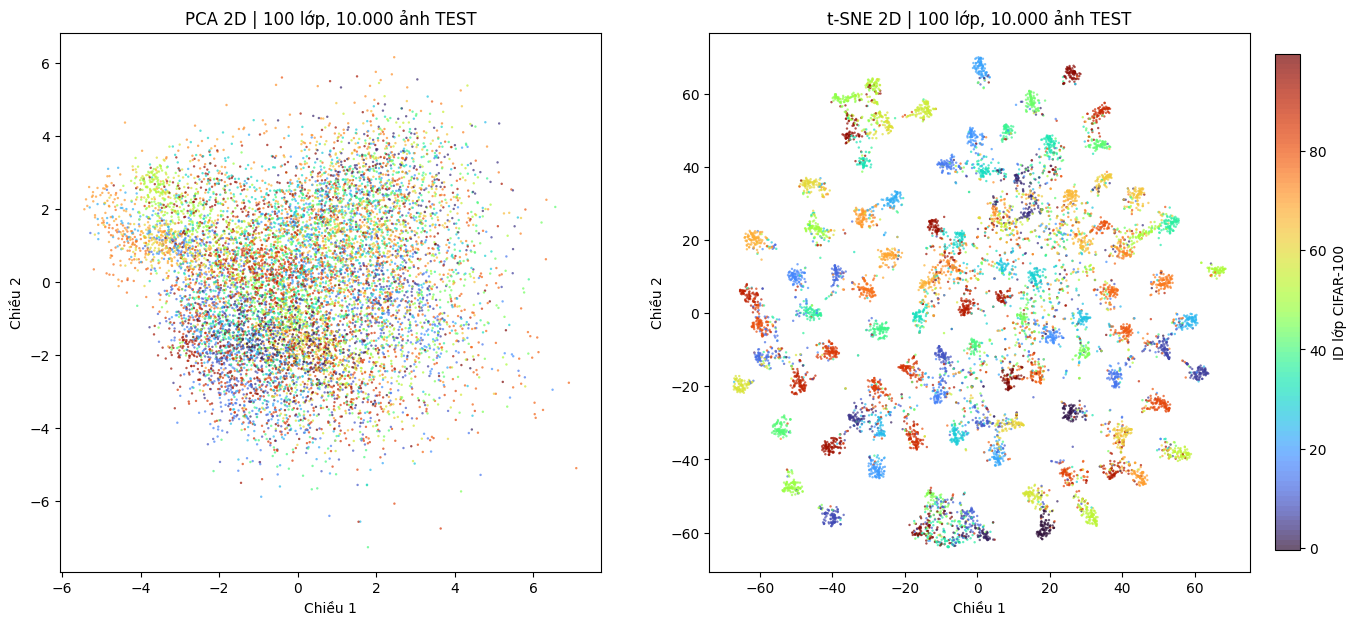

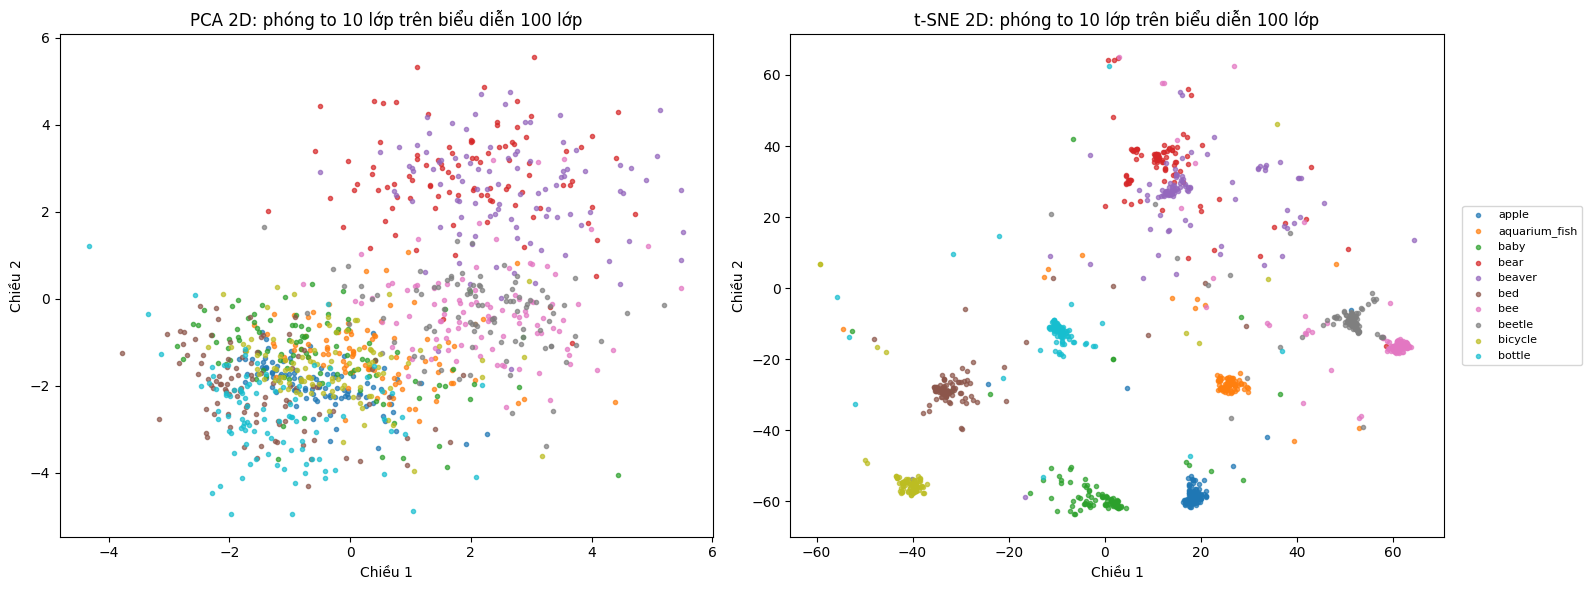

In [8]:
# PCA/t-SNE 2D: 100 lớp trên 10.000 ảnh TEST.
# Màu mã hóa class_id 0..99. Bảng tên lớp được lưu ở CSV, không nhồi 100 nhãn vào hình.
from matplotlib.colors import BoundaryNorm
palette = plt.get_cmap('turbo', 100)
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, (xy, method) in zip(axes, [(P2, 'PCA 2D'), (T2, 't-SNE 2D')]):
    dots = ax.scatter(xy[:, 0], xy[:, 1], c=y, s=3, cmap=palette,
                      vmin=-0.5, vmax=99.5, alpha=0.7, linewidths=0)
    ax.set_title(method + ' | 100 lớp, 10.000 ảnh TEST')
    ax.set_xlabel('Chiều 1'); ax.set_ylabel('Chiều 2')
fig.colorbar(dots, ax=list(axes), label='ID lớp CIFAR-100', fraction=.02, pad=.02)
fig.savefig(VIS_DIR/'all100_pca_tsne_2d.png', dpi=200, bbox_inches='tight')
plt.show()

# Phóng to 10 lớp đầu từ tọa độ được tính trên toàn bộ 100 lớp.
# Các lớp còn lại ẩn khỏi hình này, nhưng không bị loại khỏi PCA/t-SNE.
mask = np.isin(y, np.arange(10))
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
c10 = plt.get_cmap('tab10')
for ax, (xy, method) in zip(axes, [(P2, 'PCA 2D'), (T2, 't-SNE 2D')]):
    for k in range(10):
        m = y == k
        ax.scatter(xy[m, 0], xy[m, 1], color=c10(k), s=9, alpha=.7,
                   label=class_names[k])
    ax.set_title(method + ': phóng to 10 lớp trên biểu diễn 100 lớp')
    ax.set_xlabel('Chiều 1'); ax.set_ylabel('Chiều 2')
axes[1].legend(loc='center left', bbox_to_anchor=(1.02,.5), fontsize=8)
fig.tight_layout()
fig.savefig(VIS_DIR/'detail10_pca_tsne_2d.png',dpi=200,bbox_inches='tight')
plt.show()

## 8. PCA/t-SNE 3D


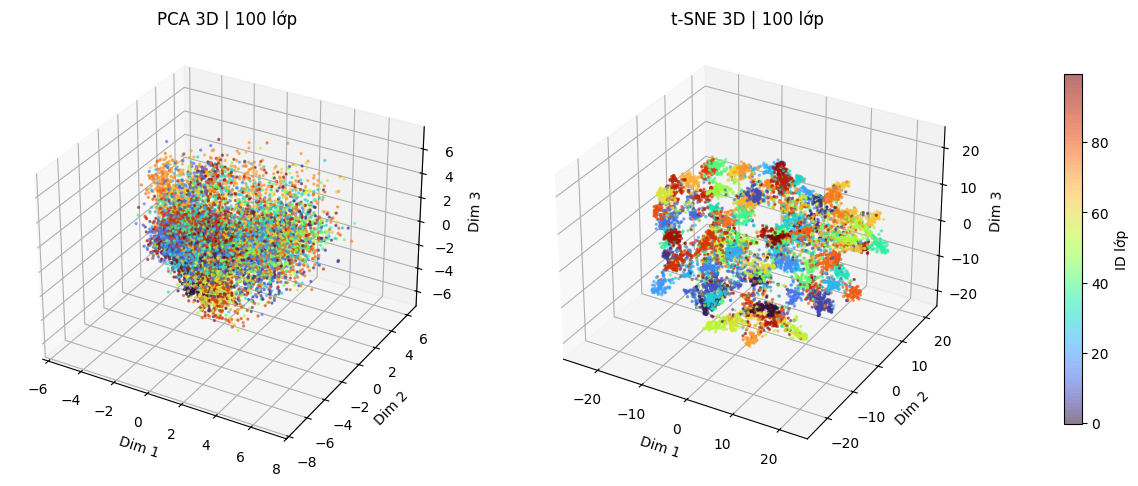

In [9]:
# PCA/t-SNE 3D của toàn bộ 100 lớp.
fig = plt.figure(figsize=(16, 7))
for j, (xyz, method) in enumerate([(P3, 'PCA 3D'), (T3, 't-SNE 3D')], 1):
    ax = fig.add_subplot(1, 2, j, projection='3d')
    dots = ax.scatter(xyz[:,0], xyz[:,1], xyz[:,2], c=y,
                      s=2, alpha=.55, cmap=palette, vmin=-.5, vmax=99.5)
    ax.set_title(method + ' | 100 lớp')
    ax.set_xlabel('Dim 1'); ax.set_ylabel('Dim 2'); ax.set_zlabel('Dim 3')
fig.colorbar(dots, ax=fig.axes, shrink=.65, pad=.08, label='ID lớp')
fig.savefig(VIS_DIR/'all100_pca_tsne_3d.png',dpi=200,bbox_inches='tight')
plt.show()

## 9. Đóng gói để tải xuống
ZIP chỉ chứa kết quả phân tích, không chứa checkpoint. Các output hiện tại được ghi lại nếu chạy lại cell.


In [10]:
save_info = {'checkpoint':str(CHECKPOINT_PATH),'model':'CIFARResNet','seed':SEED,
             'input_shape':[3,32,32],'feature_dim':128,'samples':10000,
             'mean':MEAN,'std':STD,'torch_version':str(torch.__version__),
             'note':'Inference only; no training. Test order is original CIFAR-100 order.'}
with open(VIS_DIR/'analysis_config.json','w',encoding='utf-8') as f:
    json.dump(save_info,f,ensure_ascii=False,indent=2)
archive = Path('/kaggle/working/cnn_feature_visualization.zip')
with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED) as z:
    for f in sorted(VIS_DIR.rglob('*')):
        if f.is_file(): z.write(f,arcname=f.relative_to(OUTPUT_DIR))
print('Tải kết quả tại:', archive)
from IPython.display import FileLink, display
display(FileLink(str(archive)))


Tải kết quả tại: /kaggle/working/cnn_feature_visualization.zip


/kaggle/working/cnn_feature_visualization.zip